In [ ]:
%matplotlib inline
import pathlib

import matplotlib.pyplot as plt
import plotly.express as px
import polars as pl

In [3]:
data = pl.read_csv(pathlib.Path().resolve().joinpath("data/gitt_ecm_parameters.csv"))
data

State of Charge / 1,Open-circuit voltage / V,R0 / Ohm,R1 / Ohm,Tau1 / s,Direction / 1
f64,f64,f64,f64,f64,str
0.0,2.851725,0.033364,0.115725,37.667137,"""Charge"""
0.001,2.872554,0.033239,0.117428,46.245854,"""Charge"""
0.002,2.893383,0.033115,0.119132,54.82457,"""Charge"""
0.003,2.914212,0.03299,0.120835,63.403287,"""Charge"""
0.004,2.935041,0.032866,0.122538,71.982004,"""Charge"""
…,…,…,…,…,…
0.996,4.168763,0.020967,0.015839,29.740439,"""Discharge"""
0.997,4.171242,0.02109,0.015464,31.336625,"""Discharge"""
0.998,4.17372,0.021214,0.015089,32.93281,"""Discharge"""


In [4]:
x_col = "State of Charge / 1"
c_col = "Direction / 1"
for col in data.columns:
    if col not in [x_col, c_col]:
        fig = px.scatter(data, x=x_col, y=col, color=c_col, width=1200, height=600)
        fig.show()

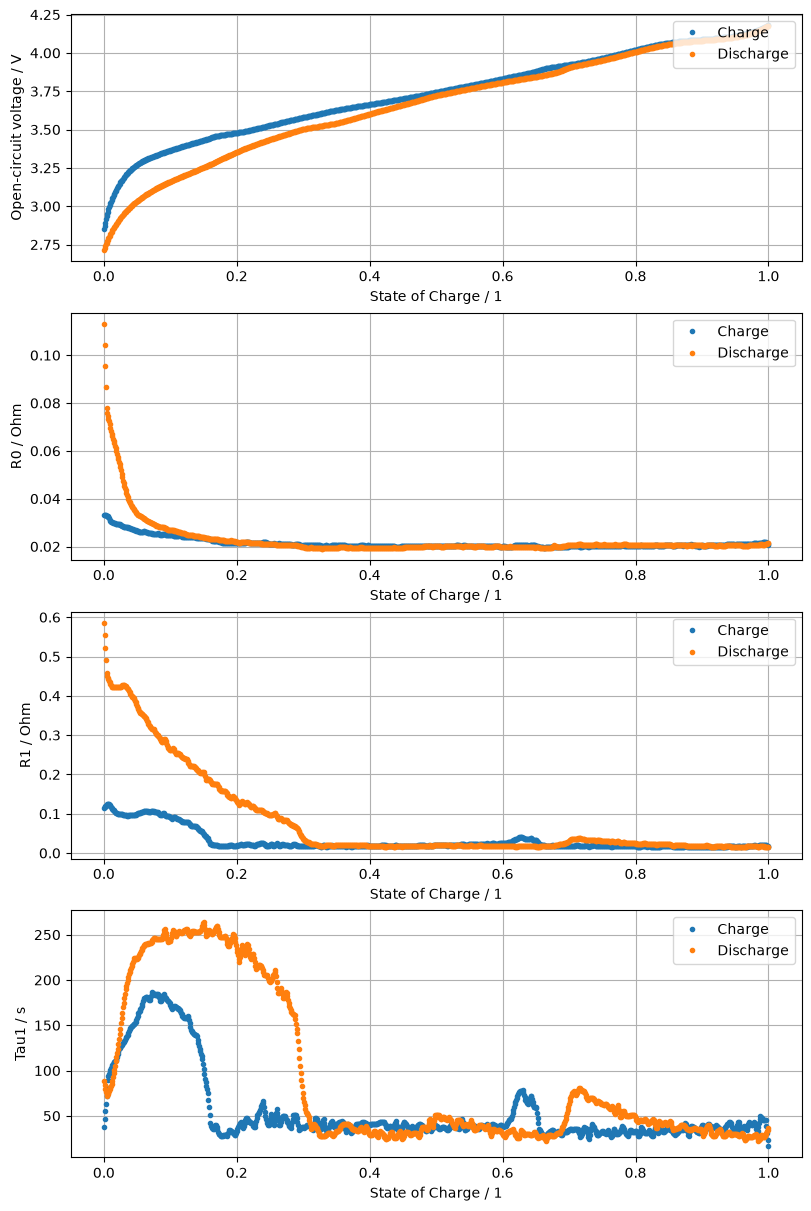

In [14]:
x_col = "State of Charge / 1"
c_col = "Direction / 1"
y_cols = [col for col in data.columns if col not in [x_col, c_col]]
fig, axs = plt.subplots(
    len(y_cols), 1, figsize=(8, 3 * len(y_cols)), constrained_layout=True, sharex=True
)
for i, (y_col, ax) in enumerate(zip(y_cols, axs)):
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.grid(True)
    for df in data.partition_by(c_col):
        ax.plot(df[x_col], df[y_col], label=f"{df[c_col][0]}", marker=".", ls="none")
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.legend(loc="upper right")